# Integer Multiples, Taylor Series, and Red-Hot Iron

> *Red-hot iron: estimate its temperature from Wien's law, taking the peak at 720 nm.*
> Options: 4000, 1000, 5000, 2000, 3000 K.

This report answers the question, then asks *why* there is a peak at all. The answer is
Planck's idea that energy comes in **integer multiples** of $hf$. A **Taylor series**
shows how classical physics is the low-frequency limit of that idea.

| § | topic | method |
|---|---|---|
| 1 | the question: Wien's law | arithmetic + an honest physics caveat |
| 2 | integer multiples → Planck's mean energy | two geometric series in **SymPy** |
| 3 | Taylor series centered at 0, and the large-x behavior | `sp.series`, `sp.limit` |
| 4 | integer arithmetic from logic: a full adder | SymPy Boolean algebra |

**References (IEEE)**
1. M. Planck, "Ueber das Gesetz der Energieverteilung im Normalspectrum," *Ann. Phys.*, vol. 309, no. 3, pp. 553–563, 1901.
2. R. D. Knight, *Physics for Scientists and Engineers: A Strategic Approach with Modern Physics*, 5th ed. Hoboken, NJ, USA: Pearson, 2022, ch. 37.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.planck_quantization_taylor import (
    x, mean_energy_symbolic, mean_energy_numeric, taylor_low_frequency, large_x_ratio_limit,
    taylor_error, wien_temperature, nearest_option, full_adder_symbolic, full_adder_truth_table, ripple_add,
)
from dgs.wien_wave_502 import wien_constant
from dgs.blackbody import planck_radiance

# 1. The question

Wien's law, $\lambda_\text{peak}T = b = 2.898\times10^{-3}$ m·K, gives
$T = b/\lambda_\text{peak}$:

In [2]:
T = wien_temperature(720)
print(f"T = {wien_constant():.4e} m·K / 720e-9 m = {T:.0f} K   →  nearest option: {nearest_option(T, [4000, 1000, 5000, 2000, 3000])} K")

T = 2.8978e-03 m·K / 720e-9 m = 4025 K   →  nearest option: 4000 K


**Answer: 4000 K**, *within the question's assumption*.

**Caveat.** The assumption, "the color you see is the peak," isn't how real red-hot iron works.
Iron glows dull red around **1000 K**, and at 1000 K the spectrum peaks at 2.9 µm, in the
infrared. What you see is only the short-wavelength **tail** leaking into the visible. A real
4000 K body would look yellowish-white, not red:

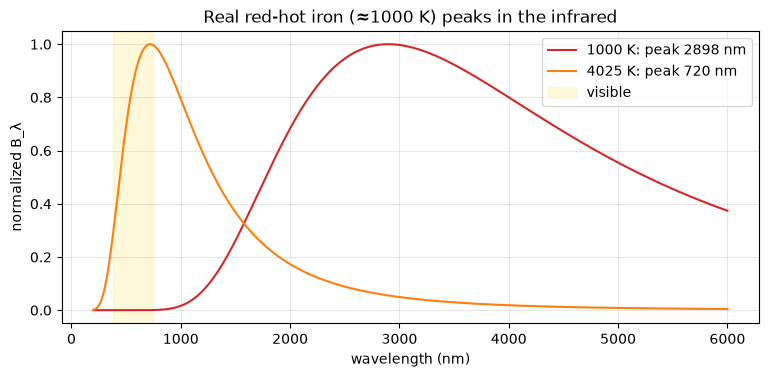

In [3]:
lam = np.linspace(200, 6000, 2000)
fig, ax = plt.subplots(figsize=(9, 3.8))
for TT, col in ((1000, "C3"), (4025, "C1")):
    B = planck_radiance(lam, TT); ax.plot(lam, B/B.max(), col, label=f"{TT} K: peak {wien_constant()/TT*1e9:.0f} nm")
ax.axvspan(380, 750, color="gold", alpha=0.15, label="visible")
ax.set(xlabel="wavelength (nm)", ylabel="normalized B_λ", title="Real red-hot iron (≈1000 K) peaks in the infrared")
ax.legend(); ax.grid(alpha=0.3); plt.show()

# 2. Why a peak? Energy in integer multiples

Classical physics gave every light mode an average energy $kT$, no matter its frequency. With
infinitely many high-frequency modes, that predicts infinite energy: the **ultraviolet
catastrophe**. Planck's fix [1] was that a mode of frequency $f$ can only hold
$E_n = n\,hf$, with $n = 0, 1, 2, \ldots$ With Boltzmann weights $e^{-E_n/kT} = r^n$, where
$r = e^{-x}$ and $x = hf/kT$:

$$\frac{\langle E\rangle}{kT} = \frac{\sum_n n\,x\,r^n}{\sum_n r^n}$$

Both sums are geometric series. SymPy can't sum $e^{-nx}$ directly because it doesn't know
$e^{-x} < 1$, so the sums are done in $r$ (convergent branch), and then $r = e^{-x}$ is
substituted back:

In [4]:
Z, S1, E = mean_energy_symbolic()
display(Math(r"\sum_{n=0}^\infty r^n = " + sp.latex(Z) + r",\qquad \sum_{n=0}^\infty n\,r^n = " + sp.latex(S1)))
display(Math(r"\frac{\langle E\rangle}{kT} = " + sp.latex(E)))
print("brute-force check, summing n = 0..1999:")
for xv in (0.1, 1.0, 4.0):
    print(f"  x = {xv}:  sum {mean_energy_numeric(xv):.10f}   formula {xv/np.expm1(xv):.10f}")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

brute-force check, summing n = 0..1999:
  x = 0.1:  sum 0.9508331945   formula 0.9508331945
  x = 1.0:  sum 0.5819767069   formula 0.5819767069
  x = 4.0:  sum 0.0746294415   formula 0.0746294415


# 3. Taylor series centered at 0, and the large-x limit

**Low frequency** ($x \to 0$): expand around $x = 0$.

**High frequency** ($x\to\infty$): look at the *leading behavior* instead of a series.

<IPython.core.display.Math object>

<IPython.core.display.Math object>

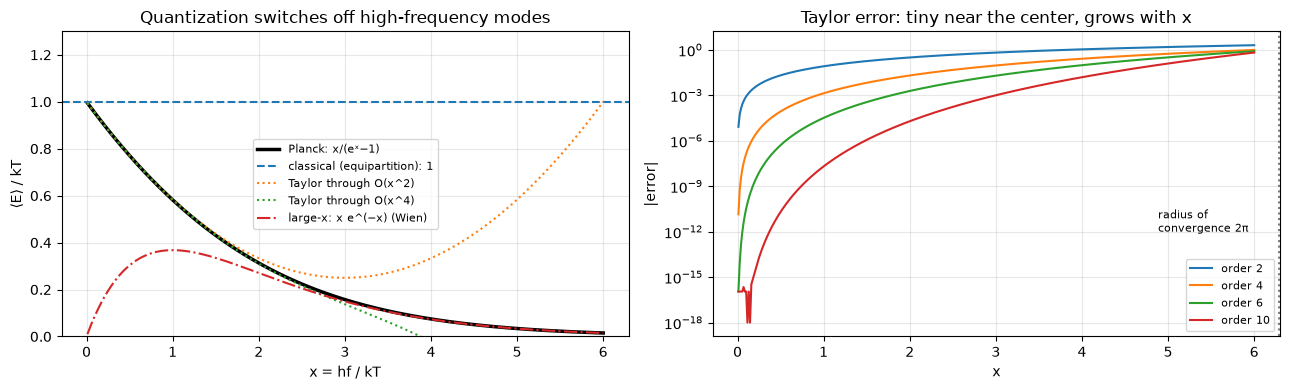

In [5]:
display(Math(r"\frac{x}{e^x - 1} = " + sp.latex(taylor_low_frequency(8))))
display(Math(r"\lim_{x\to\infty}\frac{x/(e^x-1)}{x e^{-x}} = " + sp.latex(large_x_ratio_limit())))
xs = np.linspace(0.01, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(xs, xs/np.expm1(xs), "k", lw=2.5, label="Planck: x/(eˣ−1)")
axes[0].axhline(1, color="C0", ls="--", label="classical (equipartition): 1")
for order, col in ((3, "C1"), (5, "C2")):
    s = sp.lambdify(x, taylor_low_frequency(order).removeO(), "numpy")
    axes[0].plot(xs, s(xs), col, ls=":", label=f"Taylor through O(x^{order-1})")
axes[0].plot(xs, xs*np.exp(-xs), "C3", ls="-.", label="large-x: x e^(−x) (Wien)")
axes[0].set(ylim=(0, 1.3), xlabel="x = hf / kT", ylabel="⟨E⟩ / kT", title="Quantization switches off high-frequency modes")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
for order, col in ((2, "C0"), (4, "C1"), (6, "C2"), (10, "C3")):
    axes[1].semilogy(xs, [taylor_error(v, order) + 1e-18 for v in xs], col, label=f"order {order}")
axes[1].axvline(2*np.pi, color="0.5", ls=":"); axes[1].text(2*np.pi - 1.4, 1e-12, "radius of\nconvergence 2π", fontsize=8)
axes[1].set(xlabel="x", ylabel="|error|", title="Taylor error: tiny near the center, grows with x")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

- The **first term, 1**, is classical physics. At low frequency $\langle E\rangle \to kT$, which is
  equipartition and the Rayleigh–Jeans law. Quantization only matters once $hf \sim kT$.
- **The series converges only for $|x| < 2\pi$**, because $x/(e^x-1)$ has complex poles at
  $x = \pm 2\pi i$. That's why the Taylor curves peel away at large $x$, and why the
  high-frequency end needs the *asymptotic* form $xe^{-x}$ instead.
- That exponential suppression is what makes Planck's spectrum turn over and produce a
  peak, whose position is Wien's law, the one used in §1.

# 4. Integer arithmetic from logic: a full adder

Computers build integers from bits. A **full adder** adds three bits ($a$, $b$, carry-in $c$)
into a sum bit $s$ and a carry-out:
$s = a\oplus b\oplus c$ and $c_\text{out} = ab + c(a\oplus b)$. The defining property is
**integer** arithmetic: $a + b + c = 2c_\text{out} + s$ for all 8 inputs.

In [6]:
s, cout, _ = full_adder_symbolic()
display(Math(r"s = " + sp.latex(s) + r",\qquad c_\text{out} = " + sp.latex(cout)))
df = pd.DataFrame(full_adder_truth_table(), columns=["a", "b", "c", "s", "c_out", "a+b+c", "2·c_out + s"])
display(df)
print("all rows satisfy a+b+c = 2·c_out + s:", bool((df["a+b+c"] == df["2·c_out + s"]).all()))
print(f"ripple-carry adder (8 full adders): 200 + 100 = {ripple_add(200, 100)},  255 + 255 = {ripple_add(255, 255)}")

<IPython.core.display.Math object>

,a,b,c,s,c_out,a+b+c,2·c_out + s
0,0,0,0,0,0,0,0
1,0,0,1,1,0,1,1
2,0,1,0,1,0,1,1
3,0,1,1,0,1,2,2
4,1,0,0,1,0,1,1
5,1,0,1,0,1,2,2
6,1,1,0,0,1,2,2
7,1,1,1,1,1,3,3


all rows satisfy a+b+c = 2·c_out + s: True
ripple-carry adder (8 full adders): 200 + 100 = 300,  255 + 255 = 510


The link to §2: Planck's energies are integers times $hf$, and a computer's numbers are
integers built from bits. Both are cases where "whole numbers only" changes everything,
from the shape of the blackbody spectrum to how hardware counts.

## Exercises
1. Find $T$ for a peak at 500 nm (the Sun) and at 10 µm (your skin). Which band does each fall in?
2. Expand $x^3/(e^x-1)$ (the Planck spectrum shape) around $x = 0$. What is the leading term, and which classical law is it?
3. Use `sp.series` to find the $x^6$ coefficient of $x/(e^x-1)$. These are the Bernoulli numbers $B_n/n!$.
4. Chain 4 full adders by hand for $0110 + 0111$. Check with `ripple_add(6, 7, bits=4)`.